# Calidad y preparación de datos – StreamView Analytics (EP2)

**ADY1104 · Visualización de Datos.** Este notebook revisa la calidad de los dos CSV del caso, documenta cada transformación con su antes y después y genera las tablas de `data/processed/` que se cargan en Power BI.

Principios:
- Los CSV de `data/raw/` **no se modifican**: todo se escribe en `data/processed/`.
- No se borran filas por tener nulos o valores raros: se **marcan** o se **rellenan** para que los conteos del catálogo se mantengan.
- Cada decisión queda justificada, como pide la sección 15 del caso.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path('../data/raw'); OUT = Path('../data/processed'); IMG = Path('../images')
OUT.mkdir(parents=True, exist_ok=True); IMG.mkdir(exist_ok=True)
AZUL, NARANJA = '#2a78d6', '#eb6834'   # película / serie (misma paleta que el tema de Power BI)
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 140

peli  = pd.read_csv(RAW/'netflix_movies_detailed_up_to_2025.csv')
serie = pd.read_csv(RAW/'netflix_tv_shows_detailed_up_to_2025.csv')

registro = []   # bitácora antes/después
def registrar(paso, filas, detalle):
    registro.append({'paso': paso, 'filas': filas, 'detalle': detalle})

print('Películas:', peli.shape, '| Series:', serie.shape)

Películas: (16000, 18) | Series: (16000, 16)


## 1. Diagnóstico inicial

In [2]:
nulos = pd.DataFrame({
    'peliculas_%': (peli.isna().mean()*100).round(1),
    'series_%':    (serie.isna().mean()*100).round(1)
})
nulos[(nulos > 0).any(axis=1)]

,peliculas_%,series_%
cast,1.30,7.20
country,2.90,11.20
description,0.80,20.00
director,0.80,68.50
duration,100.00,0.00
genres,0.70,6.10


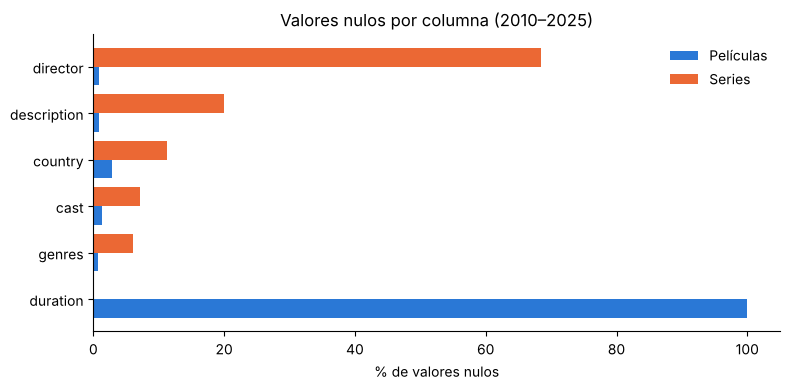

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
n = nulos[(nulos > 0).any(axis=1)].sort_values('series_%')
y = np.arange(len(n))
ax.barh(y-0.2, n['peliculas_%'], 0.4, color=AZUL, label='Películas')
ax.barh(y+0.2, n['series_%'], 0.4, color=NARANJA, label='Series')
ax.set_yticks(y); ax.set_yticklabels(n.index); ax.set_xlabel('% de valores nulos')
ax.set_title('Valores nulos por columna (2010–2025)'); ax.legend(frameon=False)
for s in ['top','right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(IMG/'nulos_por_columna.png', dpi=200); plt.show()

## 2. Columnas que no sirven: `rating` y `duration`
La regla de negocio permite excluir variables sin disponibilidad. Se comprueba con datos antes de descartar.

In [4]:
for nombre, d in [('Películas', peli), ('Series', serie)]:
    iguales = (d['rating'] == d['vote_average']).mean()
    print(f'{nombre}: rating idéntico a vote_average en {iguales:.0%} de las filas')
print('Películas con duration informada:', peli['duration'].notna().sum())
print('Series – valores de duration:', serie['duration'].value_counts().to_dict())

Películas: rating idéntico a vote_average en 100% de las filas
Series: rating idéntico a vote_average en 100% de las filas
Películas con duration informada: 0
Series – valores de duration: {'1 Seasons': 16000}


**Decisión:** `rating` repite la calificación de los usuarios (no es la clasificación etaria) y `duration` está vacía en películas y dice "1 Seasons" en todas las series. Se **excluyen ambas** y los KPIs de clasificación etaria se declaran como **no calculables**.

## 3. Duplicados e identificadores

In [5]:
print('Filas completamente duplicadas -> películas:', peli.duplicated().sum(), '| series:', serie.duplicated().sum())
comunes = set(peli.show_id) & set(serie.show_id)
print('show_id presentes en ambos archivos:', len(comunes))
print('show_id repetidos dentro de películas:', peli.show_id.duplicated().sum(), '| dentro de series:', serie.show_id.duplicated().sum())

rep = serie[serie.show_id.duplicated(keep=False)].sort_values(['show_id','popularity'], ascending=[True, False])
rep[['show_id','title','release_year','popularity','vote_count']]

Filas completamente duplicadas -> películas: 0 | series: 0
show_id presentes en ambos archivos: 397
show_id repetidos dentro de películas: 0 | dentro de series: 9


,show_id,title,release_year,popularity,vote_count
15539,252630,Joe Lycett’s United States of Birmingham,2025,11.55,0
15540,252630,Joe Lycett’s United States of Birmingham,2025,11.53,0
15360,278867,Ensemble,2025,18.41,1
15358,278867,Ensemble,2025,11.04,1
15400,279457,Ghassan & Mina,2025,16.05,0
15398,279457,Ghassan & Mina,2025,9.63,0
15479,279739,Settle Down,2025,15.21,0
15480,279739,Settle Down,2025,13.13,0
15519,280651,Master in 3 Months: Edo Period,2025,16.79,0
15520,280651,Master in 3 Months: Edo Period,2025,12.00,0


In [6]:
# Mismo título y año con distinto show_id: se revisan, pero NO se eliminan (son registros distintos del catálogo)
print('Películas con mismo título y año:', peli.duplicated(['title','release_year']).sum())
print('Series con mismo título y año   :', serie.duplicated(['title','release_year']).sum())

Películas con mismo título y año: 37
Series con mismo título y año   : 45


**Decisiones**
- Un `show_id` se repite entre películas y series (397 casos): **no es clave única global**. Se crea la clave compuesta `tipo-show_id`.
- 9 series repiten `show_id` incluso dentro de la tabla (mismo título y año, distinta popularidad): se conserva **la fila de mayor popularidad**.
- Los títulos con igual nombre y año pero distinto `show_id` se mantienen: son registros distintos.

## 4. Nulos en variables de texto

In [7]:
txt = ['director','cast','country','genres']
antes = pd.concat([peli[txt].isna().sum().rename('peliculas'), serie[txt].isna().sum().rename('series')], axis=1)
antes

,peliculas,series
director,132,10965
cast,204,1157
country,466,1797
genres,107,974


**Decisión:** no se eliminan filas. En `catalogo` los nulos de `director`, `cast`, `country` y `genres` se reemplazan por **"Sin dato"**, para que el título siga contando en los totales. Las **tablas puente excluyen "Sin dato"**, de modo que los KPIs "cantidad de países/géneros" no cuenten una categoría falsa. Consecuencia: los títulos sin país no aparecen en el análisis por país (se declara como limitación). `description` no se usa en el análisis y se deja fuera de las tablas procesadas.

**Género `Unknown`:** 99 series traen el valor literal `Unknown`, que es un nulo disfrazado. Se **excluye de `puente_genero`** (los géneros distintos pasan de 28 a 27).

## 5. Formatos y rangos

In [8]:
for nombre, d in [('Películas', peli), ('Series', serie)]:
    f = pd.to_datetime(d['date_added'], errors='coerce')
    print(f'{nombre}: fechas inválidas = {f.isna().sum()} | años release {d.release_year.min()}–{d.release_year.max()}',
          f'| vote_average fuera de 0–10 = {((d.vote_average<0)|(d.vote_average>10)).sum()}',
          f'| popularity <= 0 = {(d.popularity<=0).sum()}')
    print('   registros por año (valores únicos):', d.release_year.value_counts().unique(),
          '| año de date_added == release_year:', f'{(f.dt.year == d.release_year).mean():.0%}')

espacios = {c: int((d[c].dropna() != d[c].dropna().str.strip()).sum()) for d in [peli, serie] for c in ['director','cast']}
print('Celdas con espacios sobrantes (director/cast):', espacios)

Películas: fechas inválidas = 0 | años release 2010–2025 | vote_average fuera de 0–10 = 0 | popularity <= 0 = 0
   registros por año (valores únicos): [1000] | año de date_added == release_year: 100%
Series: fechas inválidas = 0 | años release 2010–2025 | vote_average fuera de 0–10 = 0 | popularity <= 0 = 0
   registros por año (valores únicos): [1000] | año de date_added == release_year: 100%
Celdas con espacios sobrantes (director/cast): {'director': 0, 'cast': 3}


**Decisión:** fechas y rangos son válidos. Hay exactamente **1.000 títulos por año y por tipo**, y el año de incorporación coincide con el de estreno, así que el conteo por año es plano por construcción: la evolución se mostrará con popularidad, valoración y géneros, no con cantidad. Se aplica `strip()` a las columnas de texto.

## 6. Títulos sin votos

In [9]:
for nombre, d in [('Películas', peli), ('Series', serie)]:
    sv = (d.vote_count == 0)
    print(f'{nombre}: vote_count = 0 -> {sv.sum():,} ({sv.mean():.1%})')
    print(f'   inconsistentes: votos=0 con nota>0: {((d.vote_count==0)&(d.vote_average>0)).sum()} | votos>0 con nota=0: {((d.vote_count>0)&(d.vote_average==0)).sum()}')
print()
print('Promedio de vote_average en series  -> con ceros:', round(serie.vote_average.mean(),2),
      '| solo con votos:', round(serie[serie.vote_count>0].vote_average.mean(),2))

Películas: vote_count = 0 -> 894 (5.6%)
   inconsistentes: votos=0 con nota>0: 0 | votos>0 con nota=0: 5
Series: vote_count = 0 -> 3,674 (23.0%)
   inconsistentes: votos=0 con nota>0: 13 | votos>0 con nota=0: 12

Promedio de vote_average en series  -> con ceros: 5.42 | solo con votos: 7.02


**Decisión:** no se borran; se crea `tiene_votos = vote_count > 0`. Los KPIs de valoración deben filtrar `tiene_votos = TRUE`. Sin ese filtro el promedio de series baja artificialmente. Los 30 casos inconsistentes (votos y nota que no calzan) se mantienen y se informan como limitación. Además, 1.017 títulos tienen menos de 10 votos y nota de 9 o más: los **rankings deben exigir un mínimo de votos** (propuesta: 50, que deja 15.397 títulos), configurable como parámetro en Power BI.

## 7. Presupuesto e ingresos

In [10]:
print('Películas con budget = 0 :', (peli.budget == 0).sum(), '| con revenue = 0:', (peli.revenue == 0).sum())
print('budget entre 1 y 9.999   :', peli.budget.between(1, 9999).sum(), '| revenue entre 1 y 9.999:', peli.revenue.between(1, 9999).sum())
fin_mask = (peli.budget >= 10000) & (peli.revenue >= 10000)
print('Películas con ambos >= US$10.000 (subconjunto financiero):', fin_mask.sum())

Películas con budget = 0 : 11153 | con revenue = 0: 10355


budget entre 1 y 9.999   : 85 | revenue entre 1 y 9.999: 139
Películas con ambos >= US$10.000 (subconjunto financiero): 3492


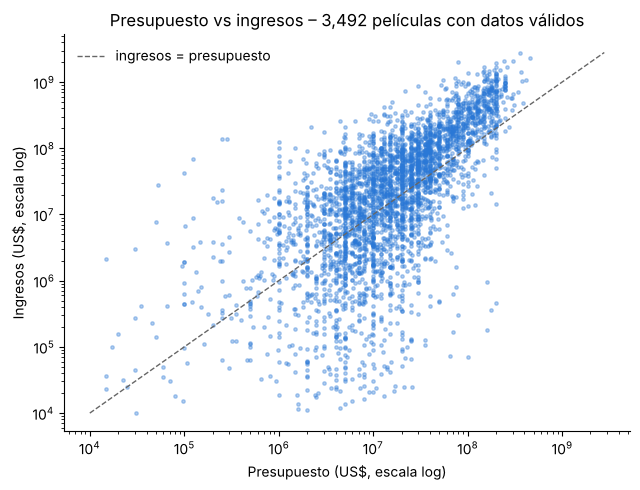

In [11]:
f = peli[fin_mask]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(f.budget, f.revenue, s=6, alpha=.35, color=AZUL)
lim = [1e4, max(f.budget.max(), f.revenue.max())]
ax.plot(lim, lim, color='#666', lw=1, ls='--', label='ingresos = presupuesto'); ax.legend(frameon=False, loc='upper left')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Presupuesto (US$, escala log)'); ax.set_ylabel('Ingresos (US$, escala log)')
ax.set_title(f'Presupuesto vs ingresos – {len(f):,} películas con datos válidos')
for s in ['top','right']: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(IMG/'presupuesto_vs_ingresos.png', dpi=200); plt.show()

**Decisión:** 11.153 películas tienen `budget = 0` y 10.355 `revenue = 0`: son **ceros que significan "sin dato"**, no gastos reales. Además hay 85 presupuestos y 139 ingresos menores a US$10.000 (probables errores de carga). Se crea `es_financiero = budget ≥ 10.000 y revenue ≥ 10.000` (3.492 películas) y `roi = revenue / budget` **solo** para ese subconjunto. Los indicadores financieros deben usar únicamente `es_financiero = TRUE`; un promedio de `budget` sin ese filtro daría un valor falso.

## 8. Valores atípicos

In [12]:
def iqr_sup(s):
    q1, q3 = s.quantile([.25, .75]); return q3 + 1.5*(q3-q1)

for nombre, d in [('Películas', peli), ('Series', serie)]:
    lim = iqr_sup(d.popularity)
    print(f'{nombre}: popularidad > {lim:,.1f} (IQR) -> {(d.popularity>lim).sum():,} títulos ({(d.popularity>lim).mean():.1%}) | máximo {d.popularity.max():,.0f}')

roi = peli[fin_mask].assign(roi=lambda x: x.revenue/x.budget)
print('\nROI (subconjunto financiero): mediana', round(roi.roi.median(),2), '| p99', round(roi.roi.quantile(.99),1), '| máx', round(roi.roi.max(),1))
print('ROI > 50:', (roi.roi>50).sum(), '| ROI < 0,01:', (roi.roi<0.01).sum())
roi.sort_values('roi', ascending=False)[['title','budget','revenue','roi']].head(5)

Películas: popularidad > 31.6 (IQR) -> 1,705 títulos (10.7%) | máximo 3,876
Series: popularidad > 118.2 (IQR) -> 1,609 títulos (10.1%) | máximo 6,422

ROI (subconjunto financiero): mediana 1.72 | p99 32.4 | máx 559.1
ROI > 50: 24 | ROI < 0,01: 77


,title,budget,revenue,roi
8803,Animal World,125000,69885700,559.09
5339,Mr. Six,250000,139191345,556.77
7238,One Cut of the Dead,52406,27590180,526.47
7739,Secret Superstar,286284,137416709,480.00
5365,The Gallows,100000,42964410,429.64


**Decisión:** la popularidad tiene una cola larga (pocos títulos muy populares), que es **información real del negocio**, no error: no se eliminan, pero en los gráficos conviene usar **mediana** o escala logarítmica. Los ROI extremos (24 sobre 50 veces; 77 bajo 0,01) también se mantienen y se señalan; el ranking de ROI debe leerse con ese contexto (películas de muy bajo presupuesto dominan el top).

## 9. Construcción de las tablas procesadas
Se aplican todas las decisiones anteriores y se registra el antes y el después de cada paso.

In [13]:
p, s = peli.copy(), serie.copy()
registrar('0. Carga original', len(p)+len(s), f'películas {len(p):,} + series {len(s):,}')

# a) quitar columnas inútiles
p = p.drop(columns=['duration','rating']); s = s.drop(columns=['duration','rating'])
registrar('1. Quitar duration y rating', len(p)+len(s), 'columnas excluidas; KPIs de clasificación etaria no calculables')

# b) limpiar espacios en texto
for d in (p, s):
    for c in ['title','director','cast','country','genres','language']:
        d[c] = d[c].str.strip()

# c) anexar y clave compuesta
cat = pd.concat([p, s], ignore_index=True)
cat['clave'] = cat['type'] + '-' + cat['show_id'].astype(str)
registrar('2. Anexar y crear clave compuesta', len(cat), 'tipo-show_id; 397 show_id repetidos entre archivos dejan de chocar')

# d) duplicados por clave: conservar la fila de mayor popularidad
n0 = len(cat)
cat = cat.sort_values('popularity', ascending=False).drop_duplicates('clave').sort_index()
registrar('3. Quitar duplicados por clave', len(cat), f'{n0-len(cat)} filas eliminadas (series con show_id repetido)')

# e) nulos de texto -> 'Sin dato' (las tablas puente los excluyen)
nulos_txt = {c: int(cat[c].isna().sum()) for c in ['director','cast','country','genres']}
puente_src = {c: cat[['clave', c]].dropna() for c in ['genres','country','director','cast']}   # antes de rellenar
for c in ['director','cast','country','genres']:
    cat[c] = cat[c].fillna('Sin dato')
registrar('4. Nulos de texto -> "Sin dato"', len(cat), f'nulos rellenados: {nulos_txt}')

# f) banderas
cat['tiene_votos'] = cat['vote_count'] > 0
cat['es_financiero'] = (cat['type'] == 'Movie') & (cat['budget'] >= 10000) & (cat['revenue'] >= 10000)
cat['roi'] = np.where(cat['es_financiero'], cat['revenue'] / cat['budget'], np.nan)
registrar('5. Banderas tiene_votos / es_financiero / roi', len(cat),
          f'sin votos: {(~cat.tiene_votos).sum():,} | financieras: {cat.es_financiero.sum():,}')

# g) fechas
cat['date_added'] = pd.to_datetime(cat['date_added'])
cat = cat.drop(columns=['description'])
registrar('6. Fecha a tipo fecha; quitar description', len(cat), 'description no se usa en el análisis')

cat.head(3)

,show_id,type,title,director,cast,country,date_added,release_year,genres,language,popularity,vote_count,vote_average,budget,revenue,clave,tiene_votos,es_financiero,roi
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,"Comedy, Adventure, Fantasy, Animation, Family",en,203.89,7449,6.38,"165,000,000.00","752,600,867.00",Movie-10192,True,True,4.56
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,"Action, Science Fiction, Adventure",en,156.24,37119,8.37,"160,000,000.00","839,030,630.00",Movie-27205,True,True,5.24
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,"Adventure, Fantasy",en,121.19,19327,7.74,"250,000,000.00","954,305,868.00",Movie-12444,True,True,3.82


In [14]:
# Tablas puente (una fila por título y valor; se excluyen los nulos originales)
def puente(col, nombre):
    t = puente_src[col].copy()
    t[col] = t[col].str.split(', ')
    t = t.explode(col)
    t[col] = t[col].str.strip()
    t = t[(t[col] != '') & (t[col] != 'Unknown')].drop_duplicates().rename(columns={col: nombre})
    return t[t.clave.isin(cat.clave)]

puentes = {
    'puente_genero':   puente('genres',   'genero'),
    'puente_pais':     puente('country',  'pais'),
    'puente_director': puente('director', 'director'),
    'puente_actor':    puente('cast',     'actor'),
}
for k, t in puentes.items():
    print(f'{k:16s} filas: {len(t):>7,} | valores distintos: {t.iloc[:,1].nunique():,}')

puente_genero    filas:  65,789 | valores distintos: 27
puente_pais      filas:  37,628 | valores distintos: 147
puente_director  filas:  24,763 | valores distintos: 14,029
puente_actor     filas: 140,367 | valores distintos: 59,710


In [15]:
# Tabla de idiomas: código ISO -> nombre
nombres = {'af':'Afrikáans','am':'Amárico','ar':'Árabe','as':'Asamés','az':'Azerí','bg':'Búlgaro','bn':'Bengalí','bs':'Bosnio',
 'ca':'Catalán','cn':'Cantonés','cs':'Checo','cy':'Galés','da':'Danés','de':'Alemán','dz':'Dzongkha','el':'Griego','en':'Inglés',
 'es':'Español','et':'Estonio','eu':'Vasco','fa':'Persa','fi':'Finés','fr':'Francés','ga':'Irlandés','gl':'Gallego','he':'Hebreo',
 'hi':'Hindi','hr':'Croata','ht':'Criollo haitiano','hu':'Húngaro','hy':'Armenio','id':'Indonesio','is':'Islandés','it':'Italiano',
 'ja':'Japonés','ka':'Georgiano','kk':'Kazajo','kl':'Groenlandés','km':'Jemer','kn':'Canarés','ko':'Coreano','ku':'Kurdo','ky':'Kirguís',
 'la':'Latín','lb':'Luxemburgués','lt':'Lituano','lv':'Letón','mi':'Maorí','mk':'Macedonio','ml':'Malayalam','mn':'Mongol','mr':'Maratí',
 'ms':'Malayo','mt':'Maltés','nb':'Noruego bokmål','ne':'Nepalí','nl':'Neerlandés','no':'Noruego','or':'Odia','pa':'Panyabí','pl':'Polaco',
 'ps':'Pastún','pt':'Portugués','ro':'Rumano','ru':'Ruso','si':'Cingalés','sk':'Eslovaco','sl':'Esloveno','sr':'Serbio','sv':'Sueco',
 'ta':'Tamil','te':'Telugu','th':'Tailandés','tl':'Tagalo','tr':'Turco','uk':'Ucraniano','ur':'Urdu','vi':'Vietnamita','xx':'Sin idioma',
 'yo':'Yoruba','za':'Zhuang','zh':'Chino','zu':'Zulú'}
dim_idioma = pd.DataFrame({'codigo_idioma': list(nombres), 'idioma': list(nombres.values())})
sin_nombre = set(cat.language) - set(nombres)
print('Códigos en los datos:', cat.language.nunique(), '| en dim_idioma:', len(dim_idioma), '| sin nombre:', sin_nombre or 'ninguno')

Códigos en los datos: 83 | en dim_idioma: 83 | sin nombre: ninguno


In [16]:
# Exportación (utf-8 con BOM para que Excel y Power BI lean bien las tildes)
cat.to_csv(OUT/'catalogo.csv', index=False, encoding='utf-8-sig')
for k, t in puentes.items(): t.to_csv(OUT/f'{k}.csv', index=False, encoding='utf-8-sig')
dim_idioma.to_csv(OUT/'dim_idioma.csv', index=False, encoding='utf-8-sig')
print(sorted(f.name for f in OUT.glob('*.csv')))

['catalogo.csv', 'dim_idioma.csv', 'kpis_referencia.csv', 'puente_actor.csv', 'puente_director.csv', 'puente_genero.csv', 'puente_pais.csv']


## 10. Bitácora antes y después

In [17]:
pd.DataFrame(registro)

,paso,filas,detalle
0,0. Carga original,32000,"películas 16,000 + series 16,000"
1,1. Quitar duration y rating,32000,columnas excluidas; KPIs de clasificación etar...
2,2. Anexar y crear clave compuesta,32000,tipo-show_id; 397 show_id repetidos entre arch...
3,3. Quitar duplicados por clave,31991,9 filas eliminadas (series con show_id repetido)
4,"4. Nulos de texto -> ""Sin dato""",31991,"nulos rellenados: {'director': 11092, 'cast': ..."
5,5. Banderas tiene_votos / es_financiero / roi,31991,"sin votos: 4,560 | financieras: 3,492"
6,6. Fecha a tipo fecha; quitar description,31991,description no se usa en el análisis


## 11. Cifras de control y KPIs de referencia
Sirven para validar las medidas de Power BI: con los filtros limpios, cada tarjeta debe dar el mismo valor.

In [18]:
v = cat[cat.tiene_votos]; fin = cat[cat.es_financiero]
kpis = [
 ('Total de contenidos',            len(cat)),
 ('Total de películas',             (cat.type=='Movie').sum()),
 ('Total de series',                (cat.type=='TV Show').sum()),
 ('Países representados',           puentes['puente_pais'].pais.nunique()),
 ('Idiomas disponibles',            cat.language.nunique()),
 ('Géneros',                        puentes['puente_genero'].genero.nunique()),
 ('Popularidad promedio',           cat.popularity.mean()),
 ('Popularidad promedio películas', cat[cat.type=='Movie'].popularity.mean()),
 ('Popularidad promedio series',    cat[cat.type=='TV Show'].popularity.mean()),
 ('Calificación promedio (con votos)',            v.vote_average.mean()),
 ('Calificación promedio películas (con votos)',  v[v.type=='Movie'].vote_average.mean()),
 ('Calificación promedio series (con votos)',     v[v.type=='TV Show'].vote_average.mean()),
 ('Títulos con votos',              len(v)),
 ('Títulos sin votos',              (~cat.tiene_votos).sum()),
 ('Películas en subconjunto financiero', len(fin)),
 ('Presupuesto promedio (US$)',     fin.budget.mean()),
 ('Presupuesto total (US$)',        fin.budget.sum()),
 ('Ingresos totales (US$)',         fin.revenue.sum()),
 ('ROI global (ingresos / presupuesto totales)', fin.revenue.sum()/fin.budget.sum()),
 ('ROI promedio por película',      fin.roi.mean()),
 ('ROI mediano por película',       fin.roi.median()),
]
kpi_ref = pd.DataFrame(kpis, columns=['kpi','valor'])
kpi_ref.to_csv(OUT/'kpis_referencia.csv', index=False, encoding='utf-8-sig')
kpi_ref

,kpi,valor
0,Total de contenidos,"31,991.00"
1,Total de películas,"16,000.00"
2,Total de series,"15,991.00"
3,Países representados,147.00
4,Idiomas disponibles,83.00
5,Géneros,27.00
6,Popularidad promedio,42.63
7,Popularidad promedio películas,20.38
8,Popularidad promedio series,64.88
9,Calificación promedio (con votos),6.63


## 12. Resumen de limitaciones
- `rating` repite `vote_average`: **no hay clasificación etaria**.
- `duration` no es utilizable.
- Conteo por año fijo (1.000 por año y tipo): no sirve para medir crecimiento.
- Títulos sin votos y 30 casos con votos y nota inconsistentes.
- Datos financieros solo para 3.492 películas; ceros interpretados como "sin dato".
- Títulos sin género, país, director o elenco quedan como "Sin dato" y no aparecen en los análisis por esas dimensiones.
- Un título con varios géneros o países cuenta en cada uno (67% tiene más de un género, 18% más de un país); los totales por género o país no suman el total de títulos.
- Películas y series usan listas de géneros distintas (Action vs Action & Adventure, Science Fiction y Fantasy vs Sci-Fi & Fantasy, War vs War & Politics): los géneros se analizan **por tipo**, no mezclados.
- 612 títulos no tienen país ni género y no aparecen en esos análisis.
- Películas con presupuesto pero sin ingresos (1.307) o al revés (2.105) quedan fuera del subconjunto financiero.
- El Top de popularidad lo encabezan programas diarios (*The Late Show*, *The Tonight Show*).
- Algunos nombres de país son antiguos o tienen errores (`Macedonia`, `Netherlands Antilles`, `Guadaloupe`) y pueden fallar en el mapa.
- `popularity` es un índice relativo de TMDB, no reproducciones.